# 📊 Explorando activos financieros con Python y pandas
## Análisis exploratorio de activos de un portafolio

En este laboratorio aprenderás a obtener datos financieros, explorarlos con **pandas**, transformarlos y encontrar información útil para analizar activos.

> **Idea clave:** primero observamos los datos, después calculamos y finalmente interpretamos.


## 🧭 Ruta de aprendizaje

**1. Conectar con los datos** → Yahoo Finance y tickers  
**2. Conocer la información** → DataFrame y estructura  
**3. Mirar antes de calcular** → exploración inicial  
**4. Seguir el comportamiento** → precios y gráficos  
**5. Medir los cambios** → rendimientos  
**6. Describir lo encontrado** → estadísticas  
**7. Comparar para comprender** → varios activos  
**8. Buscar relaciones** → correlación  
**9. Tu análisis** → misión individual


# 1. 🔌 Conectar con los datos

### ¿De dónde obtenemos la información?

Yahoo Finance contiene información histórica de diferentes activos financieros. Para acceder a ella desde Python utilizaremos **yfinance**.

Un **ticker** es el código utilizado para identificar un activo. Por ejemplo: `AAPL`, `MSFT`, `AMZN` o `GOOGL`.


In [1]:
!pip -q install yfinance

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Nuestro primer activo

Comencemos con Apple. Más adelante cambiaremos el ticker para trabajar con los activos asignados.

In [3]:
ticker = "AAPL"

datos = yf.download(
    ticker,
    start="2020-01-01",
    end="2025-01-01",
    auto_adjust=False
)

datos.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2020-01-02,72.271545,75.087502,75.150002,73.797501,74.059998,135480400
2020-01-03,71.568932,74.357498,75.144997,74.125000,74.287498,146322800
2020-01-06,72.139206,74.949997,74.989998,73.187500,73.447502,118387200
2020-01-07,71.799927,74.597504,75.224998,74.370003,74.959999,108872000
2020-01-08,72.954926,75.797501,76.110001,74.290001,74.290001,132079200


# 2. 🧩 Conocer la información

Lo que acabamos de obtener es un **DataFrame de pandas**: una estructura de datos organizada en filas y columnas.

Antes de analizar, necesitamos saber qué contiene la tabla y cómo está organizada.


In [4]:
datos.head()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2020-01-02,72.271545,75.087502,75.150002,73.797501,74.059998,135480400
2020-01-03,71.568932,74.357498,75.144997,74.125000,74.287498,146322800
2020-01-06,72.139206,74.949997,74.989998,73.187500,73.447502,118387200
2020-01-07,71.799927,74.597504,75.224998,74.370003,74.959999,108872000
2020-01-08,72.954926,75.797501,76.110001,74.290001,74.290001,132079200


In [5]:
datos.tail()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2024-12-24,256.339722,258.200012,258.209991,255.289993,255.490005,23234700
2024-12-26,257.153809,259.019989,260.100006,257.630005,258.190002,27237100
2024-12-27,253.748535,255.589996,258.700012,253.059998,257.829987,42355300
2024-12-30,250.382950,252.199997,253.500000,250.750000,252.229996,35557500
2024-12-31,248.615814,250.419998,253.279999,249.429993,252.440002,39480700


In [6]:
datos.shape

(1258, 6)

In [7]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1258 entries, 2020-01-02 to 2024-12-31
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, AAPL)  1258 non-null   float64
 1   (Close, AAPL)      1258 non-null   float64
 2   (High, AAPL)       1258 non-null   float64
 3   (Low, AAPL)        1258 non-null   float64
 4   (Open, AAPL)       1258 non-null   float64
 5   (Volume, AAPL)     1258 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 68.8 KB


### 🧠 Piensa

- ¿Qué representa una fila?
- ¿Qué representa una columna?
- ¿Qué información contiene el índice?
- ¿Cuántas observaciones tenemos?

Estas preguntas forman parte del **análisis exploratorio de datos**.

# 3. 🔎 Mirar antes de calcular

Una exploración inicial nos ayuda a detectar características, diferencias o posibles problemas antes de comenzar a realizar cálculos.

In [8]:
datos.describe()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
count,1258.000000,1258.000000,1258.000000,1258.000000,1258.000000,1.258000e+03
mean,151.247343,154.108800,155.660348,152.379123,153.951948,9.057103e+07
std,41.815935,41.520877,41.654310,41.305929,41.466618,5.324438e+07
min,54.117035,56.092499,57.125000,53.152500,57.020000,2.323470e+07
25%,126.170322,129.624996,130.755005,127.505001,129.017506,5.546825e+07
50%,149.839386,152.805000,154.570000,150.825005,152.575005,7.628335e+07
75%,175.750439,178.850006,180.160000,177.115005,178.500004,1.077425e+08
max,257.153809,259.019989,260.100006,257.630005,258.190002,4.265100e+08


In [9]:
datos.isna().sum()

,,0
Price,Ticker,
Adj Close,AAPL,0
Close,AAPL,0
High,AAPL,0
Low,AAPL,0
Open,AAPL,0
Volume,AAPL,0


### 🧠 Interpreta

No basta con ejecutar `describe()`. Observa los resultados y piensa: ¿qué nos permite conocer cada medida sobre los datos?

# 4. 📈 Seguir el comportamiento

Comencemos observando el precio de cierre. Una gráfica puede ayudarnos a identificar tendencias y cambios que serían difíciles de observar en una tabla.

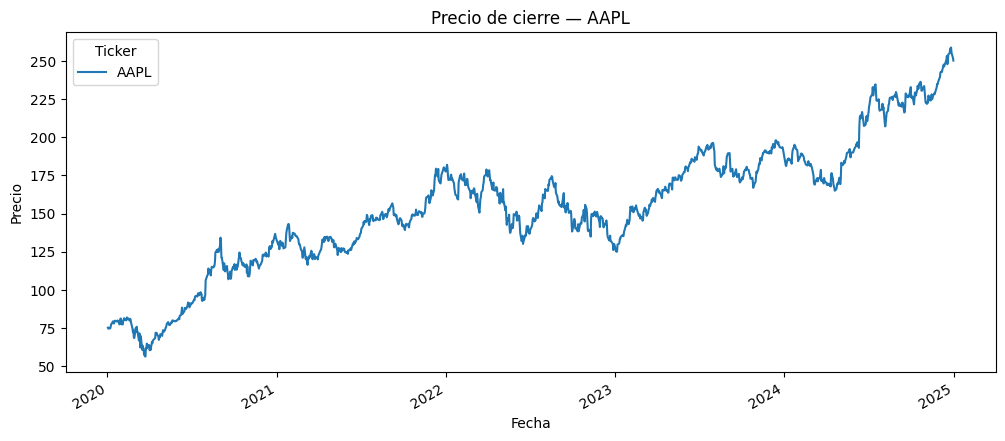

In [10]:
cierre = datos["Close"]

cierre.plot(figsize=(12, 5))
plt.title(f"Precio de cierre — {ticker}")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.show()

### 👀 Observa

Describe brevemente lo que encuentras:

- ¿Se observan períodos de crecimiento o disminución?
- ¿Hay cambios especialmente fuertes?
- ¿El comportamiento parece estable durante todo el período?


# 5. 🔄 Medir los cambios

Comparar solamente precios puede ser insuficiente porque los activos pueden comenzar con valores muy diferentes.

Una alternativa es estudiar los **rendimientos**, que expresan el cambio de una observación respecto a la anterior.


### Cálculo de Rendimientos Financieros

Existen dos formas principales de calcular los rendimientos financieros: discretos y logarítmicos.

#### 1. Rendimientos Discretos (o Simples)

Los rendimientos discretos representan el cambio porcentual en el precio de un activo entre dos períodos consecutivos. Son intuitivos y fáciles de interpretar, ya que reflejan directamente la ganancia o pérdida en relación con el precio inicial. Son adecuados para el cálculo de rendimientos de un solo período.

La fórmula para el rendimiento discreto $R_t$ en el período $t$ es:

$$\Large R_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}} - 1$$

Donde:
*   $P_t$ es el precio del activo en el tiempo $t$.
*   $P_{t-1}$ es el precio del activo en el tiempo $t-1$.

### Ejemplo de Cálculo de Rendimientos

Consideremos los siguientes precios:
*   Precio Anterior ($P_{t-1}$): **100**
*   Precio Actual ($P_t$): **110**

#### 1. Cálculo del Rendimiento Discreto

Utilizando la fórmula:

$$\Large R_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{110 - 100}{100} = \frac{10}{100} = 0.10$$

El rendimiento discreto es **0.10** o **10%**.


In [11]:
rendimiento = cierre.pct_change()
rendimiento.head()

Ticker,AAPL
Date,
2020-01-02,NaN
2020-01-03,-0.009722
2020-01-06,0.007968
2020-01-07,-0.004703
2020-01-08,0.016086


El primer valor aparece como `NaN` porque no existe una observación anterior con la cual compararlo.


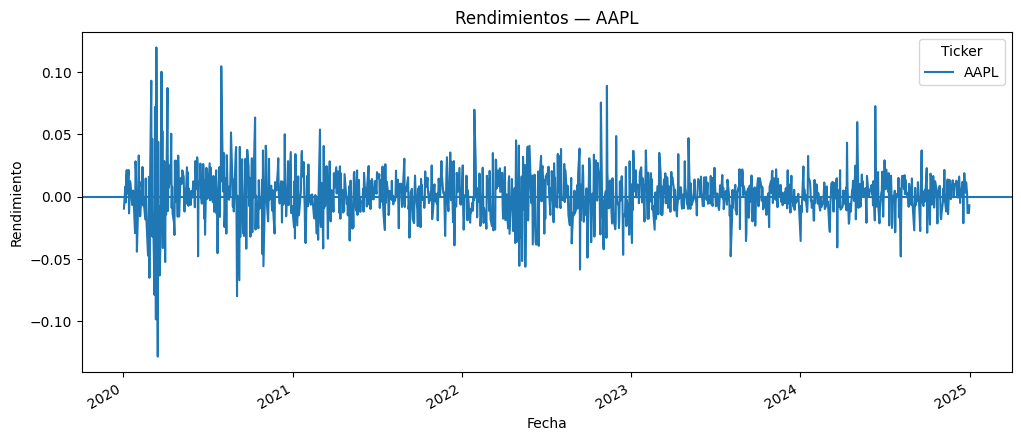

In [12]:
rendimiento.plot(figsize=(12, 5))

plt.axhline(0)
plt.title(f"Rendimientos — {ticker}")
plt.xlabel("Fecha")
plt.ylabel("Rendimiento")
plt.show()

# 6. 📐 Describir lo encontrado

Ahora podemos utilizar las estadísticas descriptivas para conocer mejor la distribución de los rendimientos.

In [13]:
rendimiento.describe()

Ticker,AAPL
count,1257.000000
mean,0.001157
std,0.019957
min,-0.128647
25%,-0.008425
50%,0.001172
75%,0.011989
max,0.119808


### Interpretación de las Estadísticas Descriptivas de Rendimientos

Al analizar la tabla de estadísticas descriptivas para los rendimientos, observamos lo siguiente:

*   **Promedio (Mean):** El promedio de los rendimientos es cercano a cero (aproximadamente 0.1157%). Esto sugiere que, a lo largo del periodo analizado, el rendimiento diario promedio del activo ha sido muy bajo, lo cual es común en series de rendimientos diarios que no muestran una tendencia marcada a largo plazo.

*   **Desviación Estándar (Std):** La desviación estándar es de aproximadamente 1.99%. Esta medida nos indica la dispersión o volatilidad de los rendimientos diarios. Un valor del 2% diario significa que, en promedio, los rendimientos suelen desviarse en un 2% (ya sea al alza o a la baja) de la media. En el contexto financiero, una mayor desviación estándar implica una mayor volatilidad y, por ende, un mayor riesgo.

*   **Mínimo (Min):** El rendimiento mínimo observado es de aproximadamente -12.86%. Esto representa la mayor pérdida porcentual experimentada por el activo en un solo día durante el periodo. Si se hubieran invertido 100 pesos, una pérdida del 12.86% implicaría que el valor de la inversión se reduciría a 87.14 pesos en ese día.

*   **Máximo (Max):** El rendimiento máximo observado es de aproximadamente 11.98%. Esta es la mayor ganancia porcentual en un solo día. Es notable que la máxima pérdida (-12.86%) es ligeramente superior a la máxima ganancia (11.98%), lo que podría indicar una asimetría en los movimientos extremos del activo, con pérdidas más severas en ciertos días.

*   **Percentil 25% (Q1):** El primer cuartil es de -0.84%. Esto significa que el 25% de los días, el rendimiento del activo fue igual o inferior a -0.84%, lo que implica una pérdida para el 25% de las observaciones.

*   **Percentil 50% (Mediana):** La mediana (percentil 50%) es de aproximadamente 0.1172%. Esto indica que el 50% de los rendimientos fueron iguales o inferiores a este valor, y el otro 50% fueron iguales o superiores. Al ser cercano a cero y ligeramente positivo, refuerza la idea de que los rendimientos oscilan alrededor de cero.

*   **Percentil 75% (Q3):** El tercer cuartil es de 1.19%. Esto significa que el 75% de los días, el rendimiento del activo fue igual o inferior a 1.19%, o dicho de otra forma, el 25% de los días la rentabilidad fue superior a 1.19%.

**Ausencia de tendencia y oscilación alrededor de cero:** Esto es típico en las series de rendimientos de activos. A diferencia de los precios, que suelen mostrar tendencias alcistas o bajistas a largo plazo, los rendimientos diarios (o periódicos) tienden a fluctuar en torno a su promedio (que a menudo es cercano a cero). Esto indica que, en el corto plazo, los movimientos positivos y negativos se compensan, sin una dirección clara y sostenida.

**Dispersión alrededor de cero y su variabilidad (Volatilidad)**: Has identificado correctamente que la dispersión de los rendimientos alrededor de cero no es constante. Esta dispersión se mide con la desviación estándar, y en el ámbito financiero se conoce como volatilidad. Una mayor dispersión (picos más altos o valles más profundos) significa mayor volatilidad, lo que implica que el precio del activo está experimentando cambios más grandes en un corto período de tiempo. Los periodos de "alta dispersión" se correlacionan con alta volatilidad (mayor riesgo), mientras que los de "baja dispersión" indican baja volatilidad (menor riesgo).

**Rangos de máximos y mínimos (Variabilidad Extrema):** La observación de que los rendimientos máximos superan el 10% y los mínimos caen por debajo del -10% es crucial. Esto te da una idea del rango extremo de movimientos que el activo ha experimentado en un solo día. Rendimientos tan altos o tan bajos en un solo día son eventos significativos que reflejan la magnitud de los shocks o noticias que afectaron al activo en esos momentos.

# Percentiles extremos


In [14]:
print("Percentil 1:", rendimiento.quantile(0.01))
print("Percentil 5:", rendimiento.quantile(0.05))

Percentil 1: Ticker
AAPL   -0.050317
Name: 0.01, dtype: float64
Percentil 5: Ticker
AAPL   -0.030125
Name: 0.05, dtype: float64


## Interpretación de Percentiles como Pérdida Máxima Esperada (VaR)

Los percentiles 1 y 5 de los rendimientos son a menudo interpretados en el contexto de **Valor en Riesgo (VaR)**, una medida clave en finanzas para cuantificar la pérdida potencial de una inversión.

*   El **percentil 1** de aproximadamente -0.050317 (-5.03%) significa que existe un **1% de probabilidad** de que el activo experimente una pérdida de 5.03% o más de su valor en un día determinado, bajo condiciones normales de mercado. Esto se puede entender como la **máxima pérdida esperada** que el activo podría sufrir con un nivel de confianza del 99% (es decir, hay solo un 1% de posibilidades de que la pérdida real sea mayor).

*   El **percentil 5** de aproximadamente -0.030125 (-3.01%) significa que existe un **5% de probabilidad** de que el activo experimente una pérdida de 3.01% o más de su valor en un día determinado. Esto se interpreta como la **máxima pérdida esperada** con un nivel de confianza del 95% (hay un 5% de posibilidades de que la pérdida real sea mayor).

En resumen, estos valores proporcionan una estimación de las pérdidas extremas que un inversor podría enfrentar con este activo en un día, junto con la probabilidad de que ocurran.

In [15]:
print("Promedio:", rendimiento.mean())
print("Desviación estándar:", rendimiento.std())
print("Mínimo:", rendimiento.min())
print("Máximo:", rendimiento.max())

Promedio: Ticker
AAPL    0.001157
dtype: float64
Desviación estándar: Ticker
AAPL    0.019957
dtype: float64
Mínimo: Ticker
AAPL   -0.128647
dtype: float64
Máximo: Ticker
AAPL    0.119808
dtype: float64


### 🧠 Interpreta

¿Qué nos dice el promedio? ¿Qué información aporta la desviación estándar? ¿Qué representan los valores mínimo y máximo?

Recuerda: **una estadística tiene sentido cuando podemos explicar qué significa en el contexto financiero.**

# 7. ⚖️ Comparar para comprender

Ahora incorporaremos varios activos. La comparación nos permitirá observar diferencias en su comportamiento.

In [16]:
activos = ["AAPL", "MSFT", "AMZN"]

datos = yf.download(
    activos,
    start="2020-01-01",
    end="2025-01-01",
    auto_adjust=False
)

precios = datos["Close"]
precios.head()

[*********************100%***********************]  3 of 3 completed


Ticker,AAPL,AMZN,MSFT
Date,,,
2020-01-02,75.087502,94.900497,160.619995
2020-01-03,74.357498,93.748497,158.619995
2020-01-06,74.949997,95.143997,159.029999
2020-01-07,74.597504,95.343002,157.580002
2020-01-08,75.797501,94.598503,160.089996


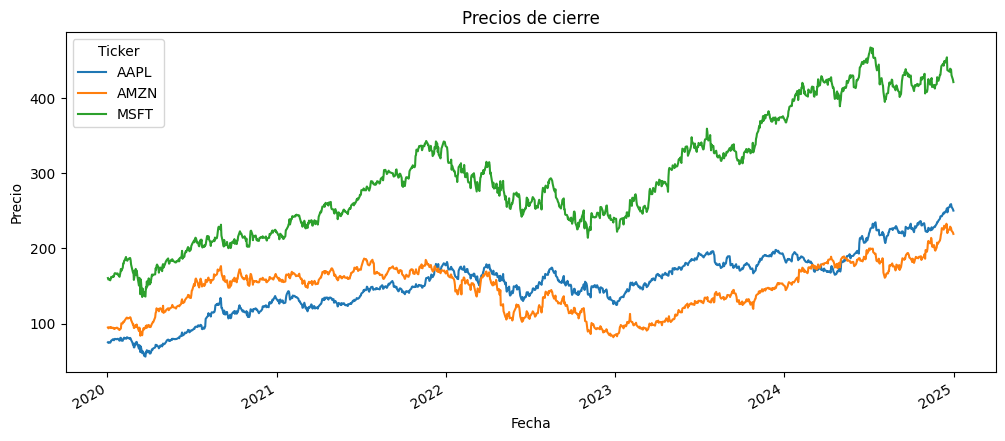

In [17]:
precios.plot(figsize=(12, 5))

plt.title("Precios de cierre")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.show()

Los precios pueden tener escalas diferentes. Para comparar su evolución desde un mismo punto de referencia podemos construir un índice base 100.

### Normalización de Precios (Base 100)

Para comparar la evolución de diferentes activos financieros, es útil **normalizar sus precios a una base común**, como 100. Esto permite observar cómo ha crecido o disminuido el valor de cada activo desde un punto de partida equitativo, independientemente de sus precios absolutos iniciales.

La fórmula para normalizar un precio $P_t$ en el tiempo $t$ a una base 100 es:

$$\Large P_{t, \text{normalizado}} = \frac{P_t}{P_0} \times 100$$

Donde:
*   $P_t$ es el precio del activo en el tiempo $t$.
*   $P_0$ es el precio inicial (o precio en el punto de partida) del activo.

#### Ejemplo:

Supongamos que tenemos los siguientes precios para un activo en tres días:

*   Día 1 ($P_0$): **75.00**
*   Día 2 ($P_1$): **74.35**
*   Día 3 ($P_2$): **74.95**

Aplicando la fórmula de normalización:

*   **Día 1:** $\frac{75.00}{75.00} \times 100 = 100$
*   **Día 2:** $\frac{74.35}{75.00} \times 100 \approx 99.13$
*   **Día 3:** $\frac{74.95}{75.00} \times 100 \approx 99.93$

Estos valores normalizados nos permiten ver el cambio porcentual relativo de cada día respecto al día inicial (base 100).

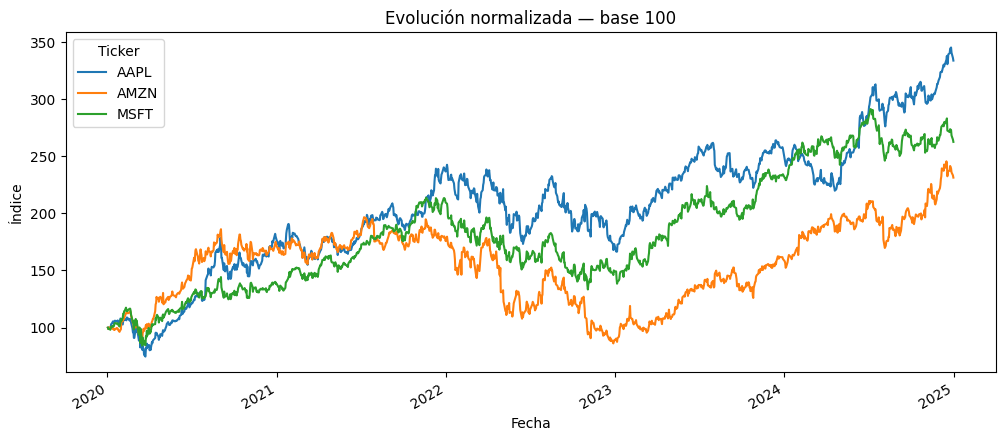

In [18]:
precios_normalizados = precios / precios.iloc[0] * 100

precios_normalizados.plot(figsize=(12, 5))
plt.title("Evolución normalizada — base 100")
plt.xlabel("Fecha")
plt.ylabel("Índice")
plt.show()

# 8. 🔗 Buscar relaciones

En un portafolio no solo importa cómo se comporta cada activo individualmente. También interesa saber cómo se relacionan entre sí.

Primero calculamos los rendimientos de todos los activos.

In [19]:
rendimientos = precios.pct_change()
rendimientos.head()

Ticker,AAPL,AMZN,MSFT
Date,,,
2020-01-02,NaN,NaN,NaN
2020-01-03,-0.009722,-0.012139,-0.012452
2020-01-06,0.007968,0.014886,0.002585
2020-01-07,-0.004703,0.002092,-0.009118
2020-01-08,0.016086,-0.007809,0.015928


In [20]:
correlacion = rendimientos.corr()
correlacion

Ticker,AAPL,AMZN,MSFT
Ticker,,,
AAPL,1.000000,0.591883,0.748121
AMZN,0.591883,1.000000,0.678666
MSFT,0.748121,0.678666,1.000000


### Análisis Financiero de la Matriz de Correlación

La matriz de correlación de los rendimientos es una herramienta fundamental en finanzas para entender la relación entre los movimientos de diferentes activos y es clave para la **diversificación de carteras**.

*   **Correlación Positiva (cercana a +1):** Indica que los rendimientos de los activos tienden a moverse en la misma dirección. Si el rendimiento de un activo sube, es muy probable que el del otro también lo haga, y viceversa. En nuestra matriz, podemos observar una fuerte correlación positiva entre **AAPL y MSFT (0.748)**. Esto significa que si las acciones de Apple suben, las de Microsoft probablemente también lo harán, y si bajan, las de Microsoft también tenderán a bajar. Una correlación alta reduce los beneficios de la diversificación, ya que los activos no actúan como "amortiguadores" el uno del otro en momentos de caída.

*   **Correlación Negativa (cercana a -1):** Sugiere que los rendimientos de los activos tienden a moverse en direcciones opuestas. Si un activo sube, el otro tiende a bajar, y viceversa. Este tipo de correlación es muy deseable para la diversificación, ya que ayuda a mitigar el riesgo de la cartera. En nuestra matriz, no observamos correlaciones negativas fuertes, lo cual es común entre acciones del mismo sector o mercado.

*   **Correlación Cero (cercana a 0):** Implica que no hay una relación lineal predecible entre los movimientos de los rendimientos de los activos. Su comportamiento es independiente el uno del otro. Aunque no reduce el riesgo tan eficazmente como una correlación negativa, sigue siendo beneficioso para la diversificación en comparación con una correlación positiva alta.

#### Implicaciones para la Diversificación:

Para construir un portafolio robusto y diversificado, se busca incluir activos con **baja o negativa correlación**. Esto se debe a que, si un activo experimenta una caída, es probable que otro activo con baja o negativa correlación no caiga (o incluso suba), compensando así parte de la pérdida. Los activos en nuestra matriz muestran correlaciones positivas entre sí, lo que sugiere que son algo dependientes. Por ejemplo, **AAPL** y **AMZN** tienen una correlación de **0.592**, y **AMZN** y **MSFT** de **0.679**. Esto indica que, aunque no se mueven en perfecta sintonía, sus rendimientos sí comparten una tendencia común.

Para mejorar la diversificación, un inversor podría considerar añadir activos de diferentes sectores, geografías o tipos (por ejemplo, bonos, materias primas) que históricamente muestren una correlación más baja o negativa con los activos tecnológicos actuales.

### ¿Cómo podemos leer la correlación?

- Cerca de **1**: los movimientos tienden a ser similares.
- Cerca de **0**: la relación lineal es débil.
- Cerca de **-1**: los movimientos tienden a ser opuestos.

### 💭 Pregunta

Si dos activos presentan una correlación elevada, ¿qué podría significar esto al pensar en diversificación?

# 9. 🚀 Tu análisis

Ahora repite el proceso con los **activos que te fueron asignados**.

Tu análisis debe seguir esta secuencia:

**Obtener → Conocer → Explorar → Transformar → Describir → Comparar → Relacionar → Interpretar**

### Tu misión

1. Obtén los datos históricos desde Yahoo Finance.
2. Explora la estructura del DataFrame.
3. Revisa los datos y los valores faltantes.
4. Observa el comportamiento de los precios.
5. Calcula los rendimientos.
6. Describe los rendimientos con estadísticas.
7. Compara visualmente los activos.
8. Explora la correlación.
9. Escribe una conclusión sustentada en los resultados.

> **Pregunta final:** ¿Qué diferencias encontraste entre los activos y qué información consideras importante conocer antes de incorporarlos a un portafolio?


In [23]:
!pip -q install yfinance

In [22]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [27]:
tickers_reto = ["ORCL","C","COP","UNH","KO","GE"]
datos_reto = yf.download(
    tickers,
    start="2020-01-01",
    end="2025-01-01",
    auto_adjust=False
)

datos_reto.head()

[*********************100%***********************]  6 of 6 completed


Price       Adj Close                                                          \
Ticker              C        COP         GE         KO       ORCL         UNH   
Date                                                                            
2020-01-02  64.339317  51.430077  57.588013  44.873505  48.798706  260.100555   
2020-01-03  63.127445  51.618645  57.781105  44.628693  48.626850  257.468414   
2020-01-06  62.929443  52.231480  58.601738  44.612366  48.880104  259.255798   
2020-01-07  62.382931  52.231480  58.167294  44.269634  48.988647  257.690674   
2020-01-08  62.858150  51.021545  57.636295  44.351242  49.179436  263.123993   

Price           Close                                   ...       Open  \
Ticker              C        COP         GE         KO  ...         GE   
Date                                                    ...              
2020-01-02  81.230003  65.459999  59.460728  54.990002  ...  55.971836   
2020-01-03  79.699997  65.699997  59.660095  54.689999  ...  57.666443   
2020-01-06  79.449997  66.480003  60.507397  54.669998  ...  59.012157   
2020-01-07  78.760002  66.480003  60.058826  54.250000  ...  60.557240   
2020-01-08  79.360001  64.940002  59.510571  54.349998  ...  59.759777   

Price                                           Volume                     \
Ticker             KO       ORCL         UNH         C      COP        GE   
Date                                                                        
2020-01-02  55.320000  53.270000  293.980011  12728900  4122800  17540015   
2020-01-03  54.320000  52.990002  287.269989  12437400  6333200  17231837   
2020-01-06  54.650002  53.360001  288.000000  10059500  8823800  22461009   
2020-01-07  54.450001  53.889999  290.700012  10469100  5974800  14160793   
2020-01-08  54.270000  53.939999  291.500000  11292400  6470100  11115771   

Price                                    
Ticker            KO      ORCL      UNH  
Date                                     
2020-01-02  11867700  13899600  2543400  
2020-01-03  11354500  11026700  2711400  
2020-01-06  14698300  10982400  3079100  
2020-01-07   9973900  12015400  2492900  
2020-01-08  10676000  11856700  3379200  

[5 rows x 36 columns]

In [30]:
datos_reto.shape

(1258, 36)

In [32]:
datos_reto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1258 entries, 2020-01-02 to 2024-12-31
Data columns (total 36 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, C)     1258 non-null   float64
 1   (Adj Close, COP)   1258 non-null   float64
 2   (Adj Close, GE)    1258 non-null   float64
 3   (Adj Close, KO)    1258 non-null   float64
 4   (Adj Close, ORCL)  1258 non-null   float64
 5   (Adj Close, UNH)   1258 non-null   float64
 6   (Close, C)         1258 non-null   float64
 7   (Close, COP)       1258 non-null   float64
 8   (Close, GE)        1258 non-null   float64
 9   (Close, KO)        1258 non-null   float64
 10  (Close, ORCL)      1258 non-null   float64
 11  (Close, UNH)       1258 non-null   float64
 12  (High, C)          1258 non-null   float64
 13  (High, COP)        1258 non-null   float64
 14  (High, GE)         1258 non-null   float64
 15  (High, KO)         1258 non-null   float64
 16  (High,

In [33]:
datos_reto.describe()

Price     Adj Close                                                      \
Ticker            C          COP           GE           KO         ORCL   
count   1258.000000  1258.000000  1258.000000  1258.000000  1258.000000   
mean      49.186271    75.546805    77.350369    51.271089    86.912587   
std        9.422372    30.423225    43.268643     7.277593    32.648825   
min       28.216982    17.937248    26.527426    30.918903    36.160023   
25%       41.407119    46.078343    48.674027    46.197384    61.864770   
50%       47.436319    86.373844    62.774321    53.094385    80.323856   
75%       58.081666   103.277542    88.834064    56.037195   108.413176   
max       69.493393   123.708290   192.003189    68.572685   188.019226   

Price                      Close                                         ...  \
Ticker          UNH            C          COP           GE           KO  ...   
count   1258.000000  1258.000000  1258.000000  1258.000000  1258.000000  ...   
mean     415.895844    56.486669    85.663728    78.858558    57.901916  ...   
std       92.624150    10.801458    31.364460    43.635739     6.166229  ...   
min      174.026459    35.389999    22.670000    27.362900    37.560001  ...   
25%      336.829926    47.209999    55.542500    49.793065    54.052500  ...   
50%      449.055145    53.985001    99.184998    64.391907    59.330000  ...   
75%      482.201653    64.905003   112.259998    90.383080    62.317500  ...   
max      596.105042    81.910004   134.940002   194.229996    73.010002  ...   

Price          Open                                               Volume  \
Ticker           GE           KO         ORCL          UNH             C   
count   1258.000000  1258.000000  1258.000000  1258.000000  1.258000e+03   
mean      78.842400    57.915556    91.397218   449.315715  1.983701e+07   
std       43.620092     6.127415    32.459497    93.184015  8.827835e+06   
min       27.960997    38.759998    41.119999   202.039993  5.941000e+06   
25%       49.489344    54.119999    66.454998   370.870003  1.399220e+07   
50%       64.404366    59.320000    85.009998   482.494995  1.798980e+07   
75%       90.606544    62.337501   112.087498   517.280014  2.390010e+07   
max      194.089996    73.300003   196.300003   619.580017  8.656620e+07   

Price                                                                         
Ticker           COP            GE            KO          ORCL           UNH  
count   1.258000e+03  1.258000e+03  1.258000e+03  1.258000e+03  1.258000e+03  
mean    7.680732e+06  1.138268e+07  1.532032e+07  1.006925e+07  3.494476e+06  
std     3.735997e+06  7.431999e+06  6.785914e+06  6.405528e+06  1.938329e+06  
min     2.159200e+06  1.981995e+06  3.265500e+06  2.168200e+06  1.135000e+06  
25%     5.309775e+06  6.192796e+06  1.126680e+07  6.341175e+06  2.448675e+06  
50%     6.716650e+06  9.565450e+06  1.383280e+07  8.204250e+06  2.981700e+06  
75%     8.927350e+06  1.395124e+07  1.726905e+07  1.139805e+07  3.816000e+06  
max     3.351510e+07  6.135574e+07  6.784570e+07  6.860570e+07  2.273420e+07  

[8 rows x 36 columns]

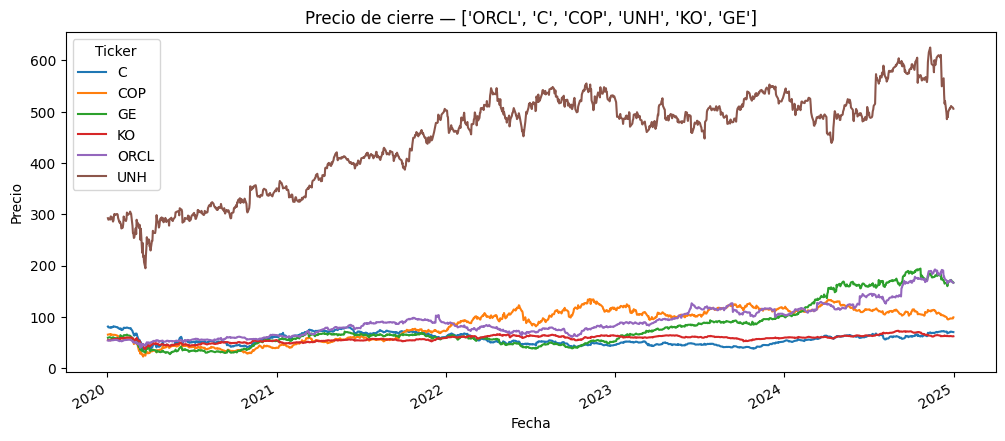

In [37]:
cierre_reto = datos_reto["Close"]

cierre_reto.plot(figsize=(12, 5))
plt.title(f"Precio de cierre — {tickers}")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.show()

In [38]:
rendimiento_reto = cierre_reto.pct_change()
rendimiento_reto.head()

Ticker,C,COP,GE,KO,ORCL,UNH
Date,,,,,,
2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,-0.018835,0.003666,0.003353,-0.005456,-0.003522,-0.010120
2020-01-06,-0.003137,0.011872,0.014202,-0.000366,0.005208,0.006942
2020-01-07,-0.008685,0.000000,-0.007413,-0.007682,0.002221,-0.006037
2020-01-08,0.007618,-0.023165,-0.009129,0.001843,-0.000554,0.021084


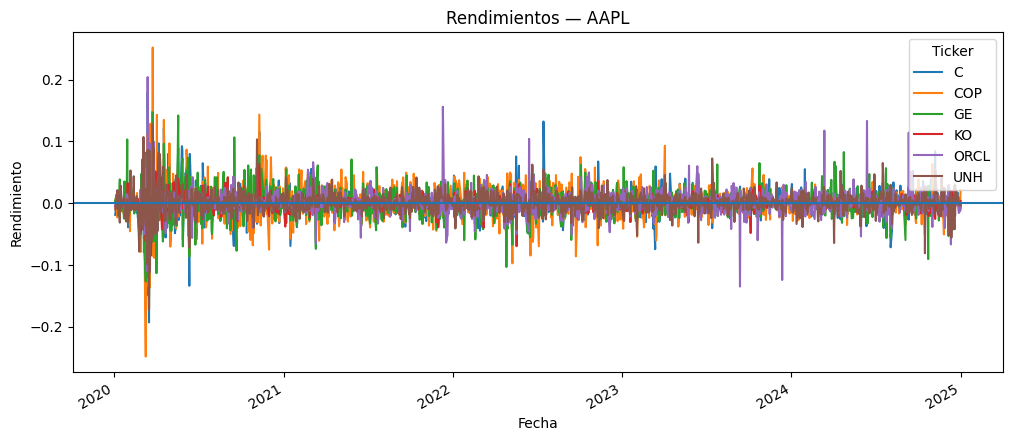

In [39]:
rendimiento_reto.plot(figsize=(12, 5))

plt.axhline(0)
plt.title(f"Rendimientos — {ticker}")
plt.xlabel("Fecha")
plt.ylabel("Rendimiento")
plt.show()

In [40]:
rendimiento_reto.describe()

Ticker,C,COP,GE,KO,ORCL,UNH
count,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000,1257.000000
mean,0.000192,0.000718,0.001129,0.000185,0.001108,0.000614
std,0.024727,0.027790,0.024828,0.013113,0.020662,0.018820
min,-0.192986,-0.248401,-0.151592,-0.096725,-0.134954,-0.172769
25%,-0.011607,-0.012433,-0.011434,-0.005462,-0.007931,-0.007596
50%,0.000000,-0.000146,0.000919,0.000688,0.001006,0.000769
75%,0.011129,0.013130,0.012838,0.006094,0.009838,0.008663
max,0.179843,0.252139,0.147300,0.064796,0.204271,0.127989


In [41]:
print("Percentil 1:", rendimiento_reto.quantile(0.01))
print("Percentil 5:", rendimiento_reto.quantile(0.05))

Percentil 1: Ticker
C      -0.061804
COP    -0.069960
GE     -0.067608
KO     -0.039287
ORCL   -0.051637
UNH    -0.051952
Name: 0.01, dtype: float64
Percentil 5: Ticker
C      -0.032711
COP    -0.037259
GE     -0.034724
KO     -0.018362
ORCL   -0.026136
UNH    -0.025454
Name: 0.05, dtype: float64


In [42]:
activos_reto =  ["ORCL","C","COP","UNH","KO","GE"]

datos_reto = yf.download(
    activos_reto,
    start="2020-01-01",
    end="2025-01-01",
    auto_adjust=False
)

precios_reto = datos_reto["Close"]
precios_reto.head()

[*********************100%***********************]  6 of 6 completed


Ticker,C,COP,GE,KO,ORCL,UNH
Date,,,,,,
2020-01-02,81.230003,65.459999,59.460728,54.990002,53.950001,292.500000
2020-01-03,79.699997,65.699997,59.660095,54.689999,53.759998,289.540009
2020-01-06,79.449997,66.480003,60.507397,54.669998,54.040001,291.549988
2020-01-07,78.760002,66.480003,60.058826,54.250000,54.160000,289.790009
2020-01-08,79.360001,64.940002,59.510571,54.349998,54.130001,295.899994


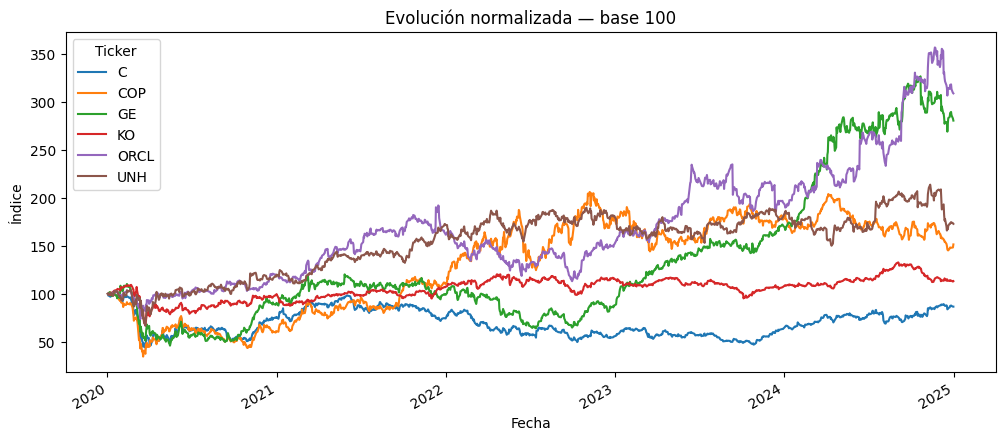

In [43]:
precios_reto_normalizados = precios_reto / precios_reto.iloc[0] * 100

precios_reto_normalizados.plot(figsize=(12, 5))
plt.title("Evolución normalizada — base 100")
plt.xlabel("Fecha")
plt.ylabel("Índice")
plt.show()

In [47]:
correlacion_reto = rendimiento_reto.corr()
correlacion_reto

Ticker,C,COP,GE,KO,ORCL,UNH
Ticker,,,,,,
C,1.000000,0.617271,0.622790,0.488299,0.387308,0.420167
COP,0.617271,1.000000,0.504059,0.366581,0.256324,0.368191
GE,0.622790,0.504059,1.000000,0.432698,0.375501,0.336877
KO,0.488299,0.366581,0.432698,1.000000,0.341993,0.488630
ORCL,0.387308,0.256324,0.375501,0.341993,1.000000,0.338668
UNH,0.420167,0.368191,0.336877,0.488630,0.338668,1.000000


## 🎫 Salida de aprendizaje

- **Encontré que…** los activos tienen comportamientos muy diversos entre sí; por ejemplo, **GE** y **ORCL** mostraron el mayor crecimiento acumulado en su evolución normalizada al final del período (superando con creces la base 100), mientras que empresas tradicionales como **KO** mantuvieron una evolución mucho más estable y de baja volatilidad (desviación estándar de ~1.31%). Por otro lado, activos como **COP** y **C** presentaron una volatilidad diaria notablemente mayor (~2.78% y ~2.47% respectivamente), exponiendo al portafolio a mayores fluctuaciones de precio y mayores pérdidas potenciales extremas en días críticos (como lo reflejan sus percentiles 1% de -6.99% y -6.18%).

- **La información que más me ayudó a comparar los activos fue…** la gráfica de **evolución normalizada (base 100)** para identificar visualmente las tendencias de crecimiento a largo plazo sin el sesgo de sus precios nominales, acompañada de la **desviación estándar de los rendimientos** para evaluar el nivel de riesgo/volatilidad individual, y los percentiles extremos (1% y 5%) que actúan como estimación del Valor en Riesgo (VaR).

- **Antes de construir un portafolio, considero importante revisar…** la **matriz de correlación** entre los activos para garantizar una diversificación efectiva (evitando juntar activos con correlaciones muy altas como **C** y **GE** o **C** y **COP** que superan el 0.61, y buscando combinar aquellos con baja correlación como **COP** y **ORCL** de 0.25), además de analizar el balance óptimo entre la rentabilidad promedio esperada de cada activo y su volatilidad histórica.